In [1]:
import pandas as pd

df_jun = pd.read_csv('nexus_ledger_436506749_Jun_2026.csv')
df_july = pd.read_csv('nexus_ledger_436506749_Jul_2026.csv')
df_aug = pd.read_csv('nexus_ledger_436506749_Aug_2026.csv')

df = pd.concat([df_jun,df_july,df_aug], ignore_index=True)
df.shape

(146, 13)

In [3]:
# 1. Define a helper function to match keywords in each text string
def categorize_strategy(reason):
    text = str(reason).upper()
    if "RSI" in text:
        return "RSI_AI"
    elif "SMC" in text or "CHOCH" in text:
        return "SMC_AI"
    elif "OB" in text:
        return "ORDER_BLOCK"
    elif "BB" in text:
        return "BOLLINGER_BANDS"
    elif "VWAP" in text:
        return "VWAP"
    else:
        return "OTHER"

# 2. Apply it across the 'Reason' column
df["Strategy_Group"] = df["Reason"].apply(categorize_strategy)

In [5]:
def calc_pf(series):
    gross_profit = series[series> 0].sum()
    gross_loss = series[series<0].sum()
    return round(gross_profit/gross_loss,2) if gross_loss > 0  else float("inf")


strategy_summary = df.groupby("Strategy_Group").agg(
    Trades = ("Net Profit",'count'),
    Total_Pnl = ('Net Profit', lambda x: round(x.sum(), 2)),
    win_rate = ("Outcome",lambda x: f"{(x== 'WIN').mean() * 100: .1f}" ),
    Avg_Pnl =  ('Net Profit',lambda x: round(x.mean(),2)),
    Profit_Factor=("Net Profit", calc_pf)
).reset_index()

print(strategy_summary)

    Strategy_Group  Trades  Total_Pnl win_rate  Avg_Pnl  Profit_Factor
0  BOLLINGER_BANDS      11     -82.89      0.0    -7.54            inf
1      ORDER_BLOCK       9     -50.51     22.2    -5.61            inf
2            OTHER       2     -12.12     50.0    -6.06            inf
3           RSI_AI      66     452.49     56.1     6.86            inf
4           SMC_AI      51     -61.79     49.0    -1.21            inf
5             VWAP       7       1.57     42.9     0.22            inf


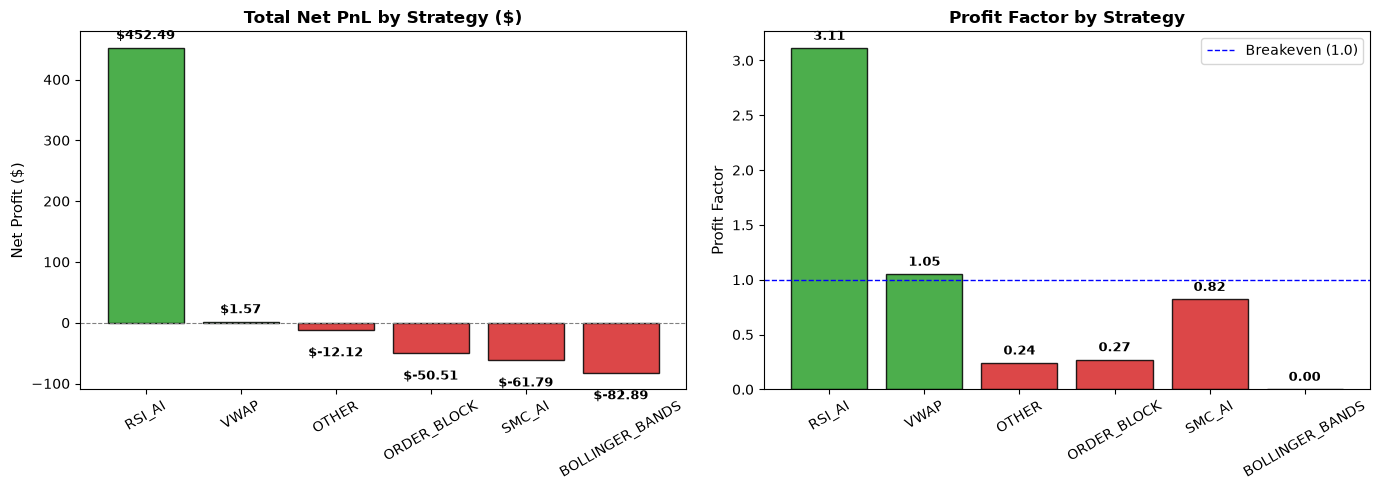

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Clean Profit Factor calculation
def calc_pf(series):
    pos = series[series > 0].sum()
    neg = abs(series[series < 0].sum())
    return round(pos / neg, 2) if neg > 0 else 0.0

# 2. Build sorted summary table
summary_df = df.groupby("Strategy_Group").apply(
    lambda g: pd.Series({
        "Trades": len(g),
        "Total_PnL": round(g["Net Profit"].sum(), 2),
        "Win_Rate": (g["Outcome"] == "WIN").mean() * 100,
        "Profit_Factor": calc_pf(g["Net Profit"])
    })
).reset_index().sort_values(by="Total_PnL", ascending=False)

# 3. Create Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Net PnL by Strategy
colors_pnl = ["#2ca02c" if x > 0 else "#d62728" for x in summary_df["Total_PnL"]]
bars1 = ax1.bar(summary_df["Strategy_Group"], summary_df["Total_PnL"], color=colors_pnl, edgecolor="black", alpha=0.85)
ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax1.set_title("Total Net PnL by Strategy ($)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Net Profit ($)", fontsize=11)
ax1.tick_params(axis="x", rotation=30)

for bar in bars1:
    h = bar.get_height()
    va = "bottom" if h >= 0 else "top"
    ax1.annotate(f"${h:,.2f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4 if h >= 0 else -12), textcoords="offset points",
                 ha="center", va=va, fontweight="bold", fontsize=9)

# Plot 2: Profit Factor by Strategy
colors_pf = ["#2ca02c" if x >= 1.0 else "#d62728" for x in summary_df["Profit_Factor"]]
bars2 = ax2.bar(summary_df["Strategy_Group"], summary_df["Profit_Factor"], color=colors_pf, edgecolor="black", alpha=0.85)
ax2.axhline(1.0, color="blue", linestyle="--", linewidth=1, label="Breakeven (1.0)")
ax2.set_title("Profit Factor by Strategy", fontsize=12, fontweight="bold")
ax2.set_ylabel("Profit Factor", fontsize=11)
ax2.tick_params(axis="x", rotation=30)
ax2.legend()

for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.show()